# 04 Operating patterns: HVAC and occupancy


HVAC switch-on/off = fastest daily temperature rise/fall; arrival/departure = fastest CO₂ rise/fall. Rates use a Savitzky–Golay derivative which smooths before differentiating so noise is not amplified.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mma3001_project.patterns import rate_of_change, daily_event, daily_profile

recon = pd.read_csv("../data/processed/sensor869_reconstructed.csv", index_col=0, parse_dates=True)
temp = recon["temp_c"]
co2 = recon["co2_ppm"]
dT = rate_of_change(temp)            # °C per hour, 70-min window
dC = rate_of_change(co2, window=9)   # ppm per hour, 90-min window (CO2 is noisier)
dT.describe().round(2)

count    15191.00
mean        -0.00
std          0.60
min         -2.18
25%         -0.32
50%         -0.00
75%          0.13
max          4.38
Name: d_temp_c_dt, dtype: float64

## 1. One week: temperature and dT/dt
Sharp positive spikes = HVAC switch-on; negative dips = switch-off.

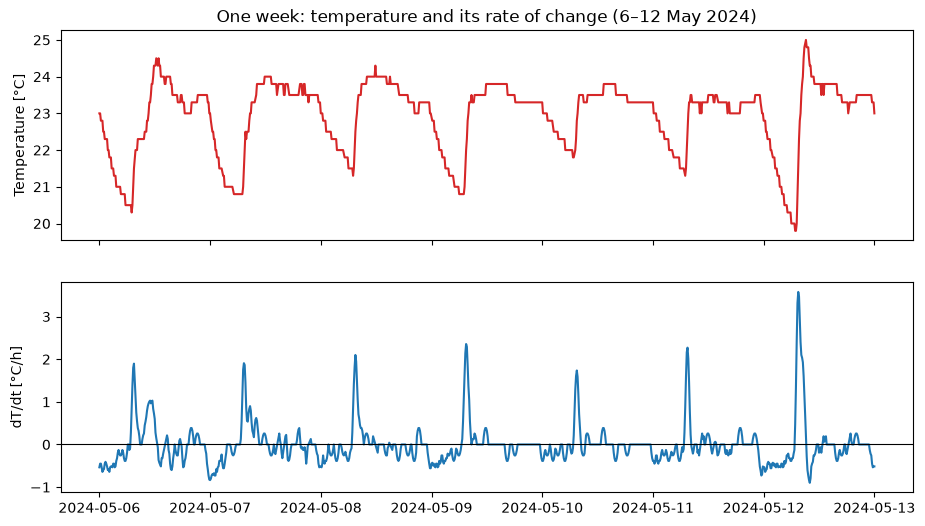

In [2]:
week = slice("2024-05-05T14:00Z", "2024-05-12T14:00Z")
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(temp[week].tz_convert("Australia/Melbourne"), color="tab:red")
axes[0].set_ylabel("Temperature [°C]")
axes[1].plot(dT[week].tz_convert("Australia/Melbourne"), color="tab:blue")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("dT/dt [°C/h]")
axes[0].set_title("One week: temperature and its rate of change (6–12 May 2024)")
os.makedirs("../figures", exist_ok=True); plt.savefig("../figures/rate_of_change_week.pdf", bbox_inches="tight"); plt.show()

## 2. Detect daily HVAC switch-on / switch-off
Search windows: on 04:00–12:00 (max rise), off 20:00–04:00 (max fall). Medians are used because a few days have late or missed switches.

In [3]:
hvac_on = daily_event(dT, start_hour=4, end_hour=12, kind="max", min_rate=0.5)   # weaker rise [°C/h] = no event
hvac_off = daily_event(dT, start_hour=20, end_hour=28, kind="min", min_rate=0.3)   # end_hour 28 = 04:00 next day
summary = pd.DataFrame({
    "HVAC on (median h)": hvac_on.groupby("weekday")["hour"].median(),
    "HVAC on (days found)": hvac_on.groupby("weekday")["hour"].count(),
    "HVAC off (median h)": hvac_off.groupby("weekday")["hour"].median(),
    "HVAC off (days found)": hvac_off.groupby("weekday")["hour"].count(),
}).rename(index={True: "weekday", False: "weekend"}).rename_axis("day type")
summary.round(2)

,HVAC on (median h),HVAC on (days found),HVAC off (median h),HVAC off (days found)
day type,,,,
weekend,7.58,30,23.75,30
weekday,7.50,73,24.00,76


**Result:** HVAC switches on ≈ 07:30 and off ≈ midnight on **weekdays and weekends alike**, i.e. a fixed 7-day timer.

## 3. Robustness checks
- **Daylight saving** (ended 7 Apr): a UTC-fixed timer would shift by 1 h in local time.
- **Smoothing window**: 50–130 min.

In [4]:
print("Before DST ended (to 6 Apr):", hvac_on.loc[:"2024-04-06", "hour"].median())
print("After DST ended (from 8 Apr):", hvac_on.loc["2024-04-08":, "hour"].median())
for w in [5, 7, 9, 13]:
    h = daily_event(rate_of_change(temp, window=w), 4, 12, "max", 0.5)["hour"]
    print(f"window {w:2d} readings ({w*10} min): median switch-on {h.median():.2f} h, days found {h.count()}")

Before DST ended (to 6 Apr): 7.666666666666667
After DST ended (from 8 Apr): 7.5
window  5 readings (50 min): median switch-on 7.50 h, days found 104
window  7 readings (70 min): median switch-on 7.50 h, days found 103
window  9 readings (90 min): median switch-on 7.67 h, days found 102
window 13 readings (130 min): median switch-on 7.67 h, days found 100


**Result:** the switch-on time moves by only 10 min across DST (7.67 → 7.50 h), so the timer runs on local time. Across window sizes the median moves ≤ 10 min and 100–104 days are detected, so results are not sensitive to the 70-min window.

## 4. Occupancy from CO₂

In [5]:
arrive = daily_event(dC, start_hour=6, end_hour=14, kind="max", min_rate=25)    # ppm/h
leave = daily_event(dC, start_hour=14, end_hour=23, kind="min", min_rate=25)
occ = pd.DataFrame({
    "arrival (median h)": arrive.groupby("weekday")["hour"].median(),
    "arrival (days found)": arrive.groupby("weekday")["hour"].count(),
    "departure (median h)": leave.groupby("weekday")["hour"].median(),
    "departure (days found)": leave.groupby("weekday")["hour"].count(),
    "days": arrive.groupby("weekday")["hour"].size(),
}).rename(index={True: "weekday", False: "weekend"}).rename_axis("day type")
occ.round(2)

,arrival (median h),arrival (days found),departure (median h),departure (days found),days
day type,,,,,
weekend,10.67,11,20.25,4,30
weekday,10.75,58,18.33,62,75


**Result:** weekday arrival ≈ 10:45 and departure ≈ 18:20. On weekends a clear arrival is found on only 11 of 30 days and a departure on 4, yet the HVAC runs every weekend. This mismatch is the energy-saving opportunity.

## 5. Average day, weekday vs weekend

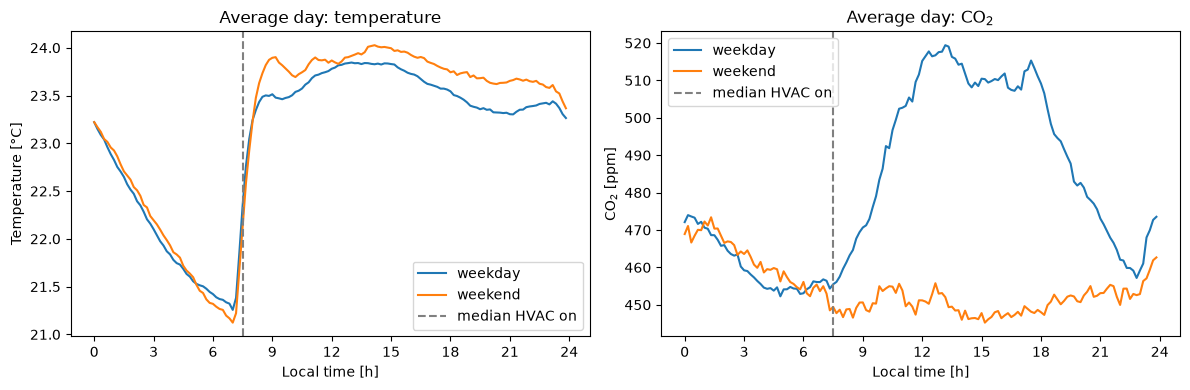

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s, label in [(axes[0], temp, "Temperature [°C]"), (axes[1], co2, "CO$_2$ [ppm]")]:
    prof = daily_profile(s)
    ax.plot(prof.index, prof["weekday"], label="weekday")
    ax.plot(prof.index, prof["weekend"], label="weekend")
    ax.axvline(hvac_on["hour"].median(), color="grey", ls="--", label="median HVAC on")
    ax.set_xlabel("Local time [h]"); ax.set_ylabel(label); ax.set_xticks(range(0, 25, 3))
    ax.legend()
axes[0].set_title("Average day: temperature"); axes[1].set_title("Average day: CO$_2$")
plt.tight_layout()
plt.savefig("../figures/average_day.pdf", bbox_inches="tight"); plt.show()

## 6. Save

In [7]:
os.makedirs("../results", exist_ok=True)
events = pd.DataFrame({"hvac_on_h": hvac_on["hour"], "hvac_off_h": hvac_off["hour"],
                       "arrival_h": arrive["hour"], "departure_h": leave["hour"]})
events["weekday"] = events.index.dayofweek < 5
events.to_csv("../results/daily_events.csv")
summary.to_csv("../results/hvac_schedule_summary.csv")
occ.to_csv("../results/occupancy_summary.csv")